# 📘 Notebook 2A — GNN & PyTorch Geometric (GCN / GAT)
*Projet Cybersécurité & NLP — Chapitre 2 (Transformers pour Texte et Graphe) — Étape 3 TDSP (Modeling)*

**Objectif métier (OM4)** : comprendre les liens entre menaces, vecteurs et cibles pour aller de la réaction vers l'anticipation.
**Objectif Data Science (DS4)** : construire un graphe traçable et entraîner un **GNN** pour classer les incidents. Mesure clé : **macro-F1 du GNN comparé au texte seul**.

**Objectifs pédagogiques :**

- Comprendre le **message passing** (un nœud agrège ses voisins) et la différence **GCN vs GAT**.
- Transformer des textes d'incidents en **graphe** (similarité sémantique + entités extraites) — lien avec le Chapitre 1 (TF-IDF, embeddings, cosinus, graphes).
- Construire l'objet **PyTorch Geometric** : `x`, `edge_index`, `y`, masques train/val/test.
- Entraîner et évaluer **MLP (sans graphe)**, **GCN**, **GAT** avec early stopping, macro-F1, matrice de confusion.
- Comparer **texte seul vs GNN** et analyser : homophilie, sur-smoothing, poids d'attention de GAT.
- Préparer l'**interface avec Walid** (données) et le **Membre 3** (GTN + Leiden).

> 🧭 **Plan** : 1) Initialisation · 2) Quiz & formules · 3) Message passing à la main · 4) Boîte à outils (modèles) · 5) Échauffement sur Cora · 6) Données cyber · 7) Étiquettes · 8) Features & baselines texte · 9) Graphes · 10) Entraînement GNN · 11) Résultats · 12) Analyses soutenance · 13) Graphe NER de Walid · 14) Export · 15) Auto-vérifications · 16) Métriques

---
## ⚙️ 1) Initialisation
Le notebook s'exécute dans l'environnement du dépôt (`pip install -e ".[dev]"`, voir `README.md`) : plus d'installation dans les cellules.
Un GPU est utilisé s'il est disponible (le notebook fonctionne aussi sur CPU). Les données viennent du **corpus nettoyé du Notebook 1** (`data/processed/corpus_clean.parquet`), commun à toute l'équipe.

In [1]:
# Initialisation commune à tous les notebooks du projet : racine du dépôt + package partagé
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from cybersec_nlp import config  # chemins et constantes partagés (data/, artifacts/, reports/)

# Imports & configuration globale
import os, re, random, itertools, warnings, json
from collections import defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns, networkx as nx
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, GATConv

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
warnings.filterwarnings("ignore")
SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Torch :", torch.__version__, "| Device :", device)

/home/magreyuptown/Projects/cybersec-NLP-GraphRAG-QA/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/magreyuptown/Projects/cybersec-NLP-GraphRAG-QA/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Torch : 2.15.0+cu132 | Device : cuda


---
# 2) Quiz & formules — GCN et GAT
Les GNN étendent aux **graphes** l'idée du Chapitre 2 : l'**attention** apprend *quoi regarder*, ici *quels voisins écouter*.

### ✅ Quiz (QCM)
Réponds en modifiant le dictionnaire `answers_student` (lettres `'A'`, `'B'` ou `'C'`), puis exécute la cellule de correction.

In [2]:
questions = [
    {"q": "Dans un GCN, un nœud met à jour sa représentation en :",
     "options": {"A": "Ignorant ses voisins", "B": "Faisant une moyenne normalisée de ses voisins (et de lui-même)", "C": "Concaténant tous les nœuds du graphe"},
     "answer": "B"},
    {"q": "La différence principale GAT vs GCN est que GAT :",
     "options": {"A": "Apprend un poids d'attention pour chaque voisin", "B": "N'utilise pas de features de nœuds", "C": "Utilise des poids fixes selon le degré"},
     "answer": "A"},
    {"q": "Avec 2 couches de message passing, un nœud « voit » :",
     "options": {"A": "Seulement ses voisins directs", "B": "Tout le graphe", "C": "Ses voisins à 1 et 2 sauts"},
     "answer": "C"},
    {"q": "Pourquoi utiliser le macro-F1 plutôt que l'accuracy ?",
     "options": {"A": "Parce que les classes d'incidents sont déséquilibrées", "B": "Parce qu'il est plus rapide à calculer", "C": "Parce qu'il ne marche que sur les graphes"},
     "answer": "A"},
    {"q": "Le sur-smoothing (over-smoothing) c'est :",
     "options": {"A": "Un manque de données d'entraînement", "B": "Trop de couches → les représentations des nœuds deviennent similaires", "C": "Un surapprentissage sur le jeu de test"},
     "answer": "B"},
    {"q": "Classification transductive : ",
     "options": {"A": "On entraîne sur un graphe et on teste sur un autre", "B": "Aucun label n'est utilisé", "C": "Le graphe entier est vu à l'entraînement, seuls les labels de test sont cachés"},
     "answer": "C"},
]

# 👉 Étudiante : renseigne tes réponses ici
answers_student = {0: "B", 1: "A", 2: "C", 3: "A", 4: "B", 5: "C"}

for i, q in enumerate(questions):
    print(f"Q{i+1}. {q['q']}")
    for k, v in q["options"].items(): print(f"   {k}) {v}")

Q1. Dans un GCN, un nœud met à jour sa représentation en :
   A) Ignorant ses voisins
   B) Faisant une moyenne normalisée de ses voisins (et de lui-même)
   C) Concaténant tous les nœuds du graphe
Q2. La différence principale GAT vs GCN est que GAT :
   A) Apprend un poids d'attention pour chaque voisin
   B) N'utilise pas de features de nœuds
   C) Utilise des poids fixes selon le degré
Q3. Avec 2 couches de message passing, un nœud « voit » :
   A) Seulement ses voisins directs
   B) Tout le graphe
   C) Ses voisins à 1 et 2 sauts
Q4. Pourquoi utiliser le macro-F1 plutôt que l'accuracy ?
   A) Parce que les classes d'incidents sont déséquilibrées
   B) Parce qu'il est plus rapide à calculer
   C) Parce qu'il ne marche que sur les graphes
Q5. Le sur-smoothing (over-smoothing) c'est :
   A) Un manque de données d'entraînement
   B) Trop de couches → les représentations des nœuds deviennent similaires
   C) Un surapprentissage sur le jeu de test
Q6. Classification transductive : 
   A)

In [3]:
#@title Correction automatique du quiz
score = 0
for i, q in enumerate(questions):
    ok = str(answers_student.get(i, "")).strip().upper() == q["answer"]
    score += ok
    print(f"Q{i+1}: {'✅' if ok else '❌'}")
print(f"\nScore : {score}/{len(questions)}")

Q1: ✅
Q2: ✅
Q3: ✅
Q4: ✅
Q5: ✅
Q6: ✅

Score : 6/6


### 🔎 Formules à connaître (soutenance)

**GCN (Kipf & Welling)** — chaque nœud fait une *moyenne normalisée* de ses voisins :
$$H^{(l+1)} = \sigma\!\left(\hat D^{-1/2}\,\hat A\,\hat D^{-1/2}\,H^{(l)}\,W^{(l)}\right),\qquad \hat A = A + I$$
- $A$ : matrice d'adjacence · $I$ : self-loops (le nœud s'écoute aussi) · $\hat D$ : degrés de $\hat A$ · $W$ : poids appris.
- Les poids de voisinage sont **fixes** (ils dépendent seulement des degrés).

**GAT (Veličković et al.)** — les poids de voisinage sont **appris par attention** :
$$e_{ij}=\text{LeakyReLU}\big(a^\top[Wh_i \,\Vert\, Wh_j]\big),\qquad \alpha_{ij}=\underset{j\in\mathcal N(i)}{\text{softmax}}(e_{ij}),\qquad h_i' = \sigma\Big(\sum_{j\in\mathcal N(i)}\alpha_{ij}\,Wh_j\Big)$$
- Même esprit que le Chapitre 2 : $\text{softmax}\big(QK^\top/\sqrt{d_k}\big)V$, mais l'attention est **limitée aux voisins** du graphe.
- **Multi-head** : plusieurs jeux d'attention en parallèle, puis concaténation (comme le Multi-Head Attention du Transformer).

> 💡 **En clair** : GCN = « je fais la moyenne de l'avis de mes voisins ». GAT = « je décide à quels voisins je fais le plus confiance ».

---
# 3) Message passing « à la main » (NumPy)
Avant PyG, refaisons **un pas de GCN** sur un mini-graphe de 4 incidents.

In [4]:
# 4 incidents ; arêtes : 0-1, 0-2, 2-3
A = np.array([[0,1,1,0],
              [1,0,0,0],
              [1,0,0,1],
              [0,0,1,0]], dtype=float)
H = np.array([[1,0],      # features (2 dimensions) de chaque incident
              [0,1],
              [1,1],
              [0,0]], dtype=float)

A_hat = A + np.eye(4)                              # 1) ajouter les self-loops
D_inv_sqrt = np.diag(1.0/np.sqrt(A_hat.sum(1)))    # 2) D^-1/2
P = D_inv_sqrt @ A_hat @ D_inv_sqrt                # 3) matrice de propagation normalisée
H1 = P @ H                                         # 4) chaque nœud agrège ses voisins

print("Matrice de propagation P :\n", np.round(P, 3))
print("\nFeatures avant :\n", H)
print("\nFeatures après 1 couche (avant W et ReLU) :\n", np.round(H1, 3))
print("\n👉 Le nœud 3 avait [0,0] ; il reçoit maintenant de l'information de son voisin 2.")

Matrice de propagation P :
 [[0.333 0.408 0.333 0.   ]
 [0.408 0.5   0.    0.   ]
 [0.333 0.    0.333 0.408]
 [0.    0.    0.408 0.5  ]]

Features avant :
 [[1. 0.]
 [0. 1.]
 [1. 1.]
 [0. 0.]]

Features après 1 couche (avant W et ReLU) :
 [[0.667 0.742]
 [0.408 0.5  ]
 [0.667 0.333]
 [0.408 0.408]]

👉 Le nœud 3 avait [0,0] ; il reçoit maintenant de l'information de son voisin 2.


---
# 4) Boîte à outils : modèles & entraînement
On définit **une seule fois** les modèles et la fonction d'entraînement, réutilisés sur Cora puis sur le graphe cyber.

- `MLP` : **aucun graphe** (référence « features seules »).
- `GCN(num_layers)` : `GCNConv` empilées.
- `GAT(heads)` : `GATConv` multi-head + méthode `attention()` pour l'interprétabilité.
- `train_eval` : entraînement avec **early stopping sur le macro-F1 de validation** (on ne regarde jamais le test pour choisir).

In [5]:
class MLP(nn.Module):
    def __init__(self, in_dim, hid, out_dim, p=0.5):
        super().__init__()
        self.l1, self.l2, self.p = nn.Linear(in_dim, hid), nn.Linear(hid, out_dim), p
    def forward(self, x, edge_index=None, return_hidden=False):
        h = F.relu(self.l1(F.dropout(x, self.p, self.training)))
        out = self.l2(F.dropout(h, self.p, self.training))
        return (out, h) if return_hidden else out

class GCN(nn.Module):
    def __init__(self, in_dim, hid, out_dim, num_layers=2, p=0.5):
        super().__init__()
        dims = [in_dim] + [hid] * (num_layers - 1) + [out_dim]
        self.convs = nn.ModuleList([GCNConv(dims[i], dims[i+1]) for i in range(num_layers)])
        self.p = p
    def forward(self, x, edge_index, return_hidden=False):
        h = x
        for conv in self.convs[:-1]:
            h = F.relu(conv(F.dropout(h, self.p, self.training), edge_index))
        out = self.convs[-1](F.dropout(h, self.p, self.training), edge_index)
        return (out, h) if return_hidden else out

class GAT(nn.Module):
    def __init__(self, in_dim, hid, out_dim, heads=4, p=0.5):
        super().__init__()
        self.conv1 = GATConv(in_dim, hid, heads=heads, dropout=p)                      # sortie : hid*heads
        self.conv2 = GATConv(hid * heads, out_dim, heads=1, concat=False, dropout=p)
        self.p = p
    def forward(self, x, edge_index, return_hidden=False):
        h = F.elu(self.conv1(F.dropout(x, self.p, self.training), edge_index))
        out = self.conv2(F.dropout(h, self.p, self.training), edge_index)
        return (out, h) if return_hidden else out
    @torch.no_grad()
    def attention(self, x, edge_index):
        # poids d'attention de la 1ère couche, moyenne sur les têtes
        self.eval()
        _, (ei, alpha) = self.conv1(x, edge_index, return_attention_weights=True)
        return ei, alpha.mean(dim=1)

In [6]:
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

def train_eval(model, data, epochs=200, lr=0.01, wd=5e-4, patience=30, class_weights=None, verbose=0):
    # Entraîne, garde le meilleur modèle (macro-F1 validation), évalue sur le test.
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    w = class_weights.to(device) if class_weights is not None else None
    y = data.y
    hist = {"train_loss": [], "val_loss": [], "val_f1": []}
    best_f1, best_state, wait = -1.0, None, 0

    for ep in range(epochs):
        model.train(); opt.zero_grad()
        out = model(data.x, data.edge_index)
        loss = F.cross_entropy(out[data.train_mask], y[data.train_mask], weight=w)
        loss.backward(); opt.step()

        model.eval()
        with torch.no_grad():
            out = model(data.x, data.edge_index)
            vloss = F.cross_entropy(out[data.val_mask], y[data.val_mask]).item()
            pred = out.argmax(1)
        vf1 = macro_f1(y[data.val_mask].cpu(), pred[data.val_mask].cpu())
        hist["train_loss"].append(loss.item()); hist["val_loss"].append(vloss); hist["val_f1"].append(vf1)

        if vf1 > best_f1:
            best_f1, wait = vf1, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
        if verbose and ep % verbose == 0:
            print(f"Epoch {ep:03d} | loss {loss.item():.3f} | val macro-F1 {vf1:.3f}")
        if wait >= patience:
            break

    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        pred = model(data.x, data.edge_index).argmax(1).cpu().numpy()
    yt = y.cpu().numpy(); te = data.test_mask.cpu().numpy()
    res = {"test_f1": macro_f1(yt[te], pred[te]), "test_acc": accuracy_score(yt[te], pred[te]),
           "val_f1": best_f1, "pred": pred, "hist": hist, "epochs": ep + 1}
    return model, res

def run_config(name, build_model, data, seeds=(0, 1, 2), **train_kw):
    # Répète l'entraînement avec plusieurs graines (init différente, même split) -> moyenne ± écart-type
    runs = []
    for s in seeds:
        set_seed(s)
        runs.append(train_eval(build_model(), data, **train_kw))
    f1s = [r["test_f1"] for _, r in runs]
    return {"name": name, "f1_mean": float(np.mean(f1s)), "f1_std": float(np.std(f1s)),
            "acc_mean": float(np.mean([r["test_acc"] for _, r in runs])),
            "val_f1_mean": float(np.mean([r["val_f1"] for _, r in runs])),
            "model": runs[0][0], "res": runs[0][1]}
print("✅ Boîte à outils prête.")

✅ Boîte à outils prête.


---
# 5) Échauffement : GCN vs GAT sur **Cora** (comme dans le Workshop)
Cora = graphe de 2 708 articles scientifiques (nœuds), liés par citations, 7 classes. C'est le « Hello World » des GNN : on vérifie notre boîte à outils avant de passer aux incidents cyber.

In [7]:
# Chargement de Cora + comparaison MLP / GCN / GAT
from torch_geometric.datasets import Planetoid
import torch_geometric.transforms as T

cora = Planetoid(root=str(config.ARTIFACTS / "datasets" / "Cora"), name="Cora", transform=T.NormalizeFeatures())
cd = cora[0].to(device)
print(f"Nœuds : {cd.num_nodes} | Arêtes : {cd.num_edges} | Features : {cora.num_node_features} | Classes : {cora.num_classes}")

cora_builders = {
    "MLP (sans graphe)": lambda: MLP(cora.num_node_features, 64, cora.num_classes),
    "GCN":               lambda: GCN(cora.num_node_features, 64, cora.num_classes),
    "GAT (8 têtes)":     lambda: GAT(cora.num_node_features, 8, cora.num_classes, heads=8),
}
cora_res = {}
for name, b in cora_builders.items():
    cora_res[name] = run_config(name, b, cd, seeds=(0, 1, 2), epochs=200, lr=0.01, wd=5e-4, patience=30)
    r = cora_res[name]
    print(f"{name:20s} test macro-F1 = {r['f1_mean']:.3f} ± {r['f1_std']:.3f} | acc = {r['acc_mean']:.3f}")
print("\n✅ Ordre de grandeur attendu : MLP ≈ 0.5-0.6, GCN/GAT ≈ 0.75-0.82 → le graphe apporte énormément quand les voisins partagent le même thème.")

Nœuds : 2708 | Arêtes : 10556 | Features : 1433 | Classes : 7


MLP (sans graphe)    test macro-F1 = 0.567 ± 0.015 | acc = 0.589


GCN                  test macro-F1 = 0.811 ± 0.008 | acc = 0.822


GAT (8 têtes)        test macro-F1 = 0.802 ± 0.017 | acc = 0.812

✅ Ordre de grandeur attendu : MLP ≈ 0.5-0.6, GCN/GAT ≈ 0.75-0.82 → le graphe apporte énormément quand les voisins partagent le même thème.


> 💡 **Ce que ça montre** : le MLP ne voit que le texte/les features de l'article ; GCN et GAT voient aussi **les articles voisins**. Notre projet cyber teste exactement la même hypothèse : *« les incidents voisins dans le graphe aident à classer un incident »*.

---
# 6) Données cyber : chargement & exploration
Dataset du sujet : **`AlicanKiraz0/Cybersecurity-Dataset-v1`** (Hugging Face, format *system / user / assistant*), **nettoyé une seule fois par le Notebook 1** (doublons, textes tronqués, balises `<think>`), avec un identifiant stable `doc_id`.

> ⚠️ **Point clé du projet** : ce dataset **n'a pas de colonne « catégorie d'incident »**. Il faut donc fabriquer les labels (section 7). Si l'équipe fournit un fichier étiqueté (colonne `label`), il est utilisé directement.

In [8]:
#  Chargement du corpus nettoyé (Notebook 1)
from cybersec_nlp.data.loading import load_clean_corpus

raw = load_clean_corpus()
print("Forme :", raw.shape)
print("Colonnes :", raw.columns.tolist())
raw.head(3)

Forme : (2194, 4)
Colonnes : ['doc_id', 'raw_index', 'user', 'assistant']


,doc_id,raw_index,user,assistant
0,HF-00000,0,Explain the fundamental data flow of a Reflect...,Reflected XSS attacks occur when an attacker s...
1,HF-00001,1,How does a Reflected XSS vulnerability in an A...,The difference between reflected cross-site sc...
2,HF-00002,2,"What is ""DOM Clobbering"" and how can it be use...",DOM Clobbering occurs when an object property ...


Lignes sans question retirées : 0
2194 incidents/questions uniques


count    2194.0
mean      451.8
std       163.7
min        34.0
25%       396.2
50%       427.0
75%       457.0
max       831.0
Name: n_words, dtype: float64


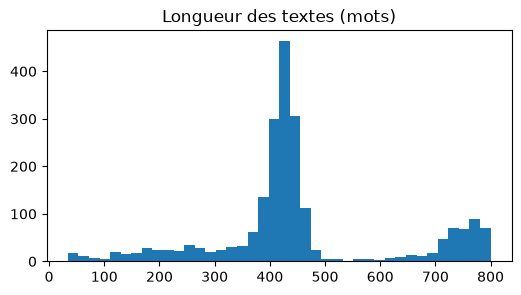


Exemple :
 Explain the fundamental data flow of a Reflected XSS attack. Describe the journey of the malicious payload from the attacker to the victim's browser, detailing each step, including the role of the web server as a reflection point. What specific trust relationship is being exploited in this process?


In [9]:
# Normalisation des colonnes -> df(question, answer, text)
if "user" in raw.columns:
    question = raw["user"]
    answer = raw["assistant"] if "assistant" in raw.columns else ""
elif "text" in raw.columns:
    question, answer = raw["text"], ""
else:
    obj = raw.select_dtypes(include=["object", "string"]).columns.tolist()
    question = raw[obj[0]]
    answer = raw[obj[1]] if len(obj) > 1 else ""

df = pd.DataFrame({"question": question, "answer": answer})
df["doc_id"] = raw["doc_id"].values            # provenance commune à toute l'équipe
if "label" in raw.columns:
    df["label_given"] = raw["label"].values

# valeurs manquantes -> chaîne vide, puis on retire les lignes sans question
n0 = len(df)
df["question"] = df["question"].fillna("").astype(str)
df["answer"] = df["answer"].fillna("").astype(str)
df = df[df["question"].str.strip().str.len() > 0]
print(f"Lignes sans question retirées : {n0 - len(df)}")

df = df.drop_duplicates(subset="question").reset_index(drop=True)
df["text"] = (df["question"] + " " + df["answer"]).str.strip()

print(f"{len(df)} incidents/questions uniques")
df["n_words"] = df["text"].str.split().str.len()
print(df["n_words"].describe().round(1))
plt.figure(figsize=(6, 3)); plt.hist(df["n_words"].clip(upper=800), bins=40); plt.title("Longueur des textes (mots)"); plt.show()
print("\nExemple :\n", df.loc[0, "question"][:300])

### Prétraitement (Chapitre 1 / TextTograph)
Même démarche que dans `TextTograph.ipynb` : minuscules → suppression de la ponctuation → tokenisation → suppression des *stop words*.
On s'en sert pour **TF-IDF** (vectorisation classique). Pour **SBERT** (embeddings contextuels) on garde le texte naturel : un Transformer a besoin de la phrase entière.

In [10]:
def clean_text(t):
    t = t.lower()
    t = re.sub(r"https?://\S+", " ", t)
    t = re.sub(r"[^\w\s]", " ", t)
    toks = [w for w in t.split() if w not in ENGLISH_STOP_WORDS and len(w) > 2]
    return " ".join(toks)

ex = df.loc[0, "question"]
print("Texte original :\n", ex[:250])
print("\nTexte prétraité :\n", clean_text(ex)[:250])

Texte original :
 Explain the fundamental data flow of a Reflected XSS attack. Describe the journey of the malicious payload from the attacker to the victim's browser, detailing each step, including the role of the web server as a reflection point. What specific trust

Texte prétraité :
 explain fundamental data flow reflected xss attack journey malicious payload attacker victim browser detailing step including role web server reflection point specific trust relationship exploited process


---
# 7) Étiquettes des incidents (supervision faible) + split
On attribue à chaque question une **catégorie** avec des règles de mots-clés (comptage de motifs par catégorie, la plus fréquente gagne).

**Deux garde-fous scientifiques** (à expliquer à l'oral) :
1. **Anti-fuite (`LEAK_GUARD`)** : les mots-clés qui ont servi à fabriquer le label sont **masqués** dans le texte donné au modèle. Sinon le modèle « relit » la règle et le score est artificiellement parfait.
2. **Graphe indépendant des règles** : les entités du graphe (section 9) ne doivent pas contenir de mot-clé de label. Un test automatique le vérifie.

Les règles d'étiquetage (catégories SOC et mots-clés) sont définies **une seule fois** dans `cybersec_nlp.nlp.classifier` : ce notebook, le pipeline et le classifieur du MVP partagent exactement les mêmes définitions.

In [11]:
#  Règles d'étiquetage (catégories d'incidents) — stems : préfixes (« phish » → phishing, phished…) | exact : mot entier
from cybersec_nlp.nlp.classifier import ALL_LABEL_RX, LABEL_RX, LABEL_SPEC, weak_label

display(pd.DataFrame([{"catégorie": c, "préfixes": ", ".join(s["stems"]), "mots exacts": ", ".join(s["exact"])}
                      for c, s in LABEL_SPEC.items()]))

if "label_given" in df.columns:
    df["label"] = df["label_given"].astype(str)
    print("✅ Labels fournis dans le fichier : utilisation directe.")
else:
    df["label"] = df["question"].apply(weak_label)
print(f"Incidents étiquetés : {df['label'].notna().sum()} / {len(df)}")
print(df["label"].value_counts())

,catégorie,préfixes,mots exacts
0,Phishing & Social Eng.,"phish, social engineering, vishing, smishing, ...",bec
1,Malware & Ransomware,"malware, ransomware, trojan, botnet, rootkit, ...",c2
2,Vulnerability & Exploit,"vulnerab, exploit, patch, zero-day, zero day, ...",rce
3,Web App Attacks,"sql injection, cross-site, injection, owasp, w...","xss, csrf, ssrf, xxe, waf"
4,Network & Intrusion,"firewall, intrusion, ddos, denial of service, ...",dns
5,Identity & Crypto,"authentic, authoriz, password, credential, enc...","mfa, sso, pki, iam, tls, ssl, oauth, saml, oidc"
6,Cloud & Governance,"cloud, container, kubernetes, compliance, gove...","aws, gcp"
7,Detection & IR (SOC),"siem, incident response, forensic, threat hunt...","soc, edr, ioc"


Incidents étiquetés : 1598 / 2194
label
Vulnerability & Exploit    632
Malware & Ransomware       277
Identity & Crypto          201
Web App Attacks            196
Detection & IR (SOC)       129
Cloud & Governance          78
Network & Intrusion         72
Phishing & Social Eng.      13
Name: count, dtype: int64


Contrôle de cohérence des règles : une question qui parle de *phishing* doit majoritairement être classée « Phishing & Social Eng. ».

In [12]:
m = df["text"].str.contains("phish", case=False)
mq = df["question"].str.contains("phish", case=False)
print("phish dans le texte :", m.sum(), "| dans la question :", mq.sum())
print(df.loc[mq, "label"].value_counts(dropna=False))
pd.set_option("display.max_colwidth", 140)
print(df.loc[mq & (df["label"] != "Phishing & Social Eng."), ["question", "label"]].head(10))

phish dans le texte : 139 | dans la question : 4
label
Phishing & Social Eng.    3
Network & Intrusion       1
Name: count, dtype: int64
                                                                                                                                        question  \
487  What is the strategic implication of DNS hijacking at a national level? Discuss how a state actor could use control over a country's pri...   

                   label  
487  Network & Intrusion  


In [13]:
MIN_PER_CLASS = 40
df = df[df["label"].notna()].copy()
keep = df["label"].value_counts()
keep = keep[keep >= MIN_PER_CLASS].index
df = df[df["label"].isin(keep)].reset_index(drop=True)

class_names = df["label"].value_counts().index.tolist()
cls2id = {c: i for i, c in enumerate(class_names)}
y = df["label"].map(cls2id).values
N, C = len(df), len(class_names)
print(f"N = {N} incidents | C = {C} classes")

LEAK_GUARD = True
df["text_feat"] = df["text"].apply(lambda t: ALL_LABEL_RX.sub(" ", t)) if LEAK_GUARD else df["text"]
assert df["text_feat"].apply(lambda t: ALL_LABEL_RX.search(t) is None).all()
print("✅ Anti-fuite actif")

N = 1585 incidents | C = 7 classes


✅ Anti-fuite actif


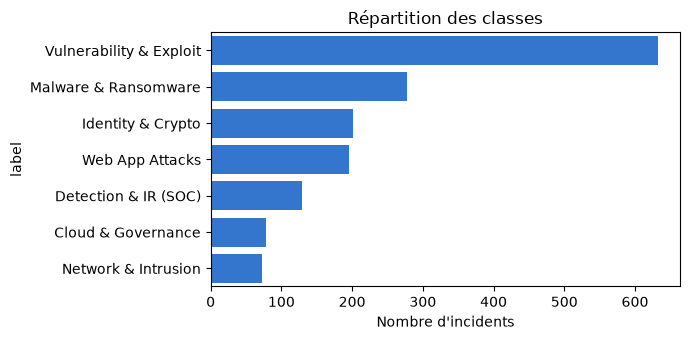

Vulnerability & Exploit    → memory, kernel, code, security, attacker, attackers, data, attacks
Malware & Ransomware       → analysis, iot, code, malicious, techniques, network, based, security
Identity & Crypto          → access, user, security, attacks, token, key, quantum, client
Web App Attacks            → user, attacker, server, xml, request, malicious, process, code
Detection & IR (SOC)       → process, memory, security, malicious, data, techniques, based, code
Cloud & Governance         → security, software, trust, organizations, access, zero, environments, data
Network & Intrusion        → network, traffic, attacks, attacker, ip, security, domain, attackers


In [14]:
# Mini-EDA : répartition des classes + mots clés par classe
counts = df["label"].value_counts()
plt.figure(figsize=(7, 3.5))
sns.barplot(x=counts.values, y=counts.index, color="#1a73e8")
plt.xlabel("Nombre d'incidents"); plt.title("Répartition des classes"); plt.tight_layout(); plt.show()

tf = TfidfVectorizer(max_features=5000, stop_words="english")
Xt = tf.fit_transform(df["text_feat"]); vocab = np.array(tf.get_feature_names_out())
for c in class_names:
    m = (df["label"] == c).values
    top = vocab[np.asarray(Xt[m].mean(axis=0)).ravel().argsort()[::-1][:8]]
    print(f"{c:26s} → {', '.join(top)}")

In [15]:
# Split stratifié train / val / test (60 / 20 / 20) — fixé une fois pour toutes
def make_split(y, seed=SEED, train=0.6, val=0.2):
    idx = np.arange(len(y))
    tr, tmp = train_test_split(idx, train_size=train, stratify=y, random_state=seed)
    va, te = train_test_split(tmp, test_size=(1 - train - val) / (1 - train), stratify=y[tmp], random_state=seed)
    return tr, va, te

idx_train, idx_val, idx_test = make_split(y)
print(f"train {len(idx_train)} | val {len(idx_val)} | test {len(idx_test)}")

train 951 | val 317 | test 317


---
# 8) Features `x` & baselines **texte seul**
Chapitre 1 : transformer un texte en vecteur.

| Méthode | Type (cours) | Usage ici |
|---|---|---|
| **TF-IDF** (+ SVD) | simple / statistique | baseline « texte seul » |
| **SBERT** (`all-MiniLM-L6-v2`) | embedding **contextuel** (Transformer) | features `x` des nœuds + graphe kNN |

Les baselines **texte seul** donnent le score à battre pour DS4 (*macro-F1 du GNN vs texte seul*).

In [16]:
# Embeddings SBERT (features des nœuds)
from sentence_transformers import SentenceTransformer
sbert = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=str(device))
X_sbert = sbert.encode(df["text_feat"].tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
print("X_sbert :", X_sbert.shape)

X_gnn = StandardScaler().fit_transform(X_sbert)      # standardisation (non supervisée) pour un apprentissage stable
IN_DIM = X_gnn.shape[1]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2372.30it/s]

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Batches:   4%|▍         | 1/25 [00:00<00:05,  4.46it/s]

Batches:   8%|▊         | 2/25 [00:00<00:04,  5.51it/s]

Batches:  12%|█▏        | 3/25 [00:00<00:03,  5.72it/s]

... (20 outputs left out)

Batches:  96%|█████████▌| 24/25 [00:03<00:00,  7.39it/s]

Batches: 100%|██████████| 25/25 [00:03<00:00,  8.01it/s]

Batches: 100%|██████████| 25/25 [00:03<00:00,  6.94it/s]

X_sbert : (1585, 384)


In [17]:
# Baselines texte seul : TF-IDF + LogReg, SBERT + LogReg
df["text_clean"] = df["text_feat"].apply(clean_text)
yt = y[idx_test]
results = []          # tableau de résultats global

# 1) TF-IDF + Régression logistique (TF-IDF ajusté sur le TRAIN uniquement)
pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=30000)),
                 ("lr", LogisticRegression(max_iter=2000, class_weight="balanced"))])
pipe.fit(df["text_clean"].iloc[idx_train], y[idx_train])
p = pipe.predict(df["text_clean"].iloc[idx_test])
results.append({"Modèle": "TF-IDF + LogReg", "Famille": "Texte seul", "Graphe": "—", "macro-F1": macro_f1(yt, p), "±": 0.0, "Accuracy": accuracy_score(yt, p), "val_f1": np.nan})

# 2) SBERT + Régression logistique
lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_sbert[idx_train], y[idx_train])
p = lr.predict(X_sbert[idx_test])
results.append({"Modèle": "SBERT + LogReg", "Famille": "Texte seul", "Graphe": "—", "macro-F1": macro_f1(yt, p), "±": 0.0, "Accuracy": accuracy_score(yt, p), "val_f1": np.nan})

pd.DataFrame(results)[["Modèle", "macro-F1", "Accuracy"]].round(3)

,Modèle,macro-F1,Accuracy
0,TF-IDF + LogReg,0.509,0.596
1,SBERT + LogReg,0.425,0.476


---
# 9) Construction des graphes (Chapitre 1 : *du texte au graphe*)
Nœuds = incidents. On construit **trois graphes** et on compare leur impact (c'est un résultat à présenter : *« impact de la qualité du graphe sur le macro-F1 »*).

| Graphe | Arêtes | Type (cours) | Dépendance |
|---|---|---|---|
| **A. kNN sémantique** | chaque incident ↔ ses *k* plus proches (cosinus SBERT) | graphe de similarité | aucune |
| **B. Entités partagées** | deux incidents liés s'ils partagent une entité (CVE, IP, ATT&CK, outil/malware, produit…) | graphe entité-incident (projeté) | remplaçable par le NER de Walid |
| **C. Hybride** | A ∪ B | texte + graphe | — |

> 💡 On mesure l'**homophilie** d'arête = % d'arêtes reliant deux incidents **de même classe**. Plus elle est haute, plus un GNN a de chances d'aider.

In [18]:
# Utilitaires graphe (NumPy)
def undirected_unique(ei):
    ei = np.asarray(ei, dtype=np.int64).reshape(2, -1)
    both = np.concatenate([ei, ei[::-1]], axis=1)
    both = both[:, both[0] != both[1]]                  # pas de self-loop (PyG les ajoute lui-même)
    return np.unique(both, axis=1) if both.shape[1] else both

def knn_edges(X, k=10):
    nbrs = NearestNeighbors(n_neighbors=k + 1, metric="cosine").fit(X)
    _, idx = nbrs.kneighbors(X)
    src = np.repeat(np.arange(len(X)), k)
    dst = idx[:, 1:].reshape(-1)
    return undirected_unique(np.vstack([src, dst]))

def edge_homophily(ei, y):
    return float(np.mean(y[ei[0]] == y[ei[1]])) if ei.shape[1] else float("nan")

def graph_stats(name, ei, y):
    deg = np.bincount(ei[0], minlength=len(y)) if ei.shape[1] else np.zeros(len(y), int)
    return {"Graphe": name, "Arêtes": ei.shape[1] // 2, "Degré moyen": round(float(deg.mean()), 2),
            "Nœuds isolés": int((deg == 0).sum()), "Homophilie": round(edge_homophily(ei, y), 3)}

# Graphe A : kNN sémantique
K = 10
ei_knn = knn_edges(X_sbert, k=K)
print(f"Graphe A (kNN, k={K}) : {ei_knn.shape[1] // 2} arêtes")

Graphe A (kNN, k=10) : 11744 arêtes


In [19]:
# Graphe B : entités extraites (regex + lexique) -> projection incident-incident
ENTITY_LEXICON = {
  "TOOL_MALWARE": ["mimikatz", "cobalt strike", "emotet", "wannacry", "notpetya", "lockbit", "conti", "ryuk", "trickbot", "stuxnet", "metasploit", "bloodhound", "nmap", "sliver", "qakbot", "revil", "mirai", "agent tesla", "njrat", "redline", "wireshark", "burp suite", "nessus", "shodan", "sqlmap", "hydra", "hashcat", "john the ripper", "psexec", "impacket", "responder", "powersploit"],
  "ACTOR":        ["apt28", "apt29", "apt41", "lazarus", "sandworm", "fin7", "turla", "fancy bear", "cozy bear", "scattered spider"],
  "PRODUCT":      ["windows", "linux", "macos", "android", "ios", "active directory", "exchange", "sharepoint", "office 365", "apache", "nginx", "tomcat", "wordpress", "mysql", "postgresql", "mongodb", "redis", "oracle", "vmware", "cisco", "fortinet", "palo alto", "citrix", "chrome", "firefox", "java", "python", "php", "log4j", "struts", "openssl", "docker", "jenkins", "github", "gitlab", "splunk", "elastic", "crowdstrike", "wazuh", "snort", "suricata", "zeek", "powershell", "ssh", "rdp", "smb", "ftp", "ldap", "kerberos", "ntlm", "bluetooth"],
  "NAMED_VULN":   ["log4shell", "heartbleed", "eternalblue", "shellshock", "spectre", "meltdown", "solarwinds", "proxylogon", "printnightmare", "zerologon"],
  "TACTIC":       ["initial access", "execution", "persistence", "defense evasion", "credential access", "discovery", "collection", "exfiltration", "impact"],
}
ENTITY_REGEX = {"CVE": re.compile(r"\bCVE-\d{4}-\d{4,7}\b", re.I),
                "IP": re.compile(r"\b(?:\d{1,3}\.){3}\d{1,3}\b"),
                "ATTACK_ID": re.compile(r"\bT\d{4}(?:\.\d{3})?\b")}

# 🔒 Garde-fou anti-fuite : on retire du lexique tout terme qui est aussi un mot-clé d'étiquetage
dropped, LEX_RX = [], {}
for typ, terms in ENTITY_LEXICON.items():
    ok = [t for t in terms if not ALL_LABEL_RX.search(t)]
    dropped += [t for t in terms if ALL_LABEL_RX.search(t)]
    LEX_RX[typ] = re.compile(r"\b(?:" + "|".join(re.escape(t) for t in ok) + r")\b", re.I)
print("Termes retirés (conflit avec les règles d'étiquetage) :", dropped)

def extract_entities(text):
    ents = set()
    for typ, rx in ENTITY_REGEX.items():
        ents |= {f"{typ}:{m.upper()}" for m in rx.findall(text)}
    for typ, rx in LEX_RX.items():
        ents |= {f"{typ}:{m.lower()}" for m in rx.findall(text)}
    return ents

df["entities"] = df["text"].apply(extract_entities)
print(f"Incidents avec ≥1 entité : {(df['entities'].str.len() > 0).mean():.1%} | entités distinctes : {len(set().union(*df['entities']))}")

# Projection : entité partagée par 2..MAX_DF incidents -> clique entre ces incidents (les « hubs » trop fréquents sont ignorés)
MIN_DF, MAX_DF = 2, 60
inv = defaultdict(list)
for i, ents in enumerate(df["entities"]):
    for e in ents: inv[e].append(i)
pairs, kept = set(), 0
for e, docs in inv.items():
    if MIN_DF <= len(docs) <= MAX_DF:
        kept += 1
        pairs.update(itertools.combinations(docs, 2))
ei_ent = undirected_unique(np.array(sorted(pairs)).T) if pairs else np.zeros((2, 0), dtype=np.int64)
print(f"Entités retenues : {kept} | Graphe B : {ei_ent.shape[1] // 2} arêtes")

ei_hyb = undirected_unique(np.concatenate([ei_knn, ei_ent], axis=1))     # Graphe C = A ∪ B

Termes retirés (conflit avec les règles d'étiquetage) : ['credential access']


Incidents avec ≥1 entité : 72.7% | entités distinctes : 244
Entités retenues : 97 | Graphe B : 13469 arêtes


In [20]:
# Graphe D : entités extraites par le NER du Notebook 1 (Walid) -> projection incident-incident
# Même garde-fou anti-fuite : toute entité qui contient un mot-clé d'étiquetage est ignorée.
walid_entities = {r["doc_id"]: {f'{e["label"]}:{e["key"]}' for e in r["entities"]}
                  for r in json.load(open(config.ENTITIES_JSON, encoding="utf-8"))}
df["entities_ner"] = df["doc_id"].map(lambda d: {e for e in walid_entities.get(d, set())
                                                 if not ALL_LABEL_RX.search(e.split(":", 1)[1])})
inv_w = defaultdict(list)
for i, ents in enumerate(df["entities_ner"]):
    for e in ents:
        inv_w[e].append(i)
pairs_w = set()
for docs in inv_w.values():
    if MIN_DF <= len(docs) <= MAX_DF:
        pairs_w.update(itertools.combinations(docs, 2))
ei_walid = undirected_unique(np.array(sorted(pairs_w)).T) if pairs_w else np.zeros((2, 0), dtype=np.int64)
print(f"Incidents avec ≥1 entité NER : {(df['entities_ner'].str.len() > 0).mean():.1%} | Graphe D : {ei_walid.shape[1] // 2} arêtes")

Incidents avec ≥1 entité NER : 67.1% | Graphe D : 11956 arêtes


In [21]:
# Comparaison des graphes (stats + homophilie)
graph_edges = {"A. kNN": ei_knn, "B. Entités": ei_ent, "C. Hybride": ei_hyb, "D. NER Walid": ei_walid}
gstats = pd.DataFrame([graph_stats(n, e, y) for n, e in graph_edges.items()])
gstats

,Graphe,Arêtes,Degré moyen,Nœuds isolés,Homophilie
0,A. kNN,11744,14.82,0,0.453
1,B. Entités,13469,17.00,952,0.339
2,C. Hybride,24120,30.44,0,0.387
3,D. NER Walid,11956,15.09,870,0.346


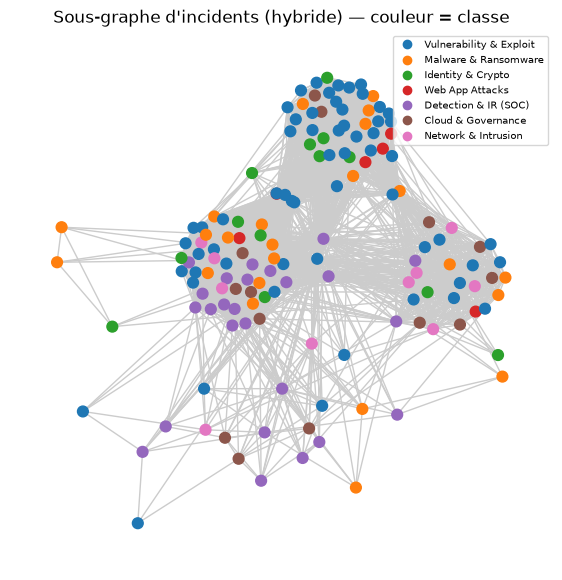

In [22]:
# Visualisation d'un sous-graphe (couleur = classe) — comme dans TextTograph
G = nx.Graph(); G.add_nodes_from(range(N)); G.add_edges_from(ei_hyb.T.tolist())
hub = int(np.argmax(np.bincount(ei_hyb[0], minlength=N)))
sub = list(nx.single_source_shortest_path_length(G, hub, cutoff=2).keys())[:150]
H = G.subgraph(sub)
pos = nx.spring_layout(H, seed=SEED)
plt.figure(figsize=(7, 7))
nx.draw_networkx(H, pos, node_color=[y[n] for n in H.nodes()], cmap=plt.cm.tab10, vmin=0, vmax=9, node_size=60, with_labels=False, edge_color="0.8")
handles = [plt.Line2D([0], [0], marker="o", ls="", color=plt.cm.tab10(i / 9), label=c) for i, c in enumerate(class_names)]
plt.legend(handles=handles, fontsize=7, loc="best"); plt.title("Sous-graphe d'incidents (hybride) — couleur = classe"); plt.axis("off"); plt.show()

---
# 10) Objet PyTorch Geometric & entraînement GNN
**`Data(x, edge_index, y)`** :
- `x` : features des nœuds `[N, 384]` (embedding SBERT),
- `edge_index` : arêtes `[2, E]` (ligne 0 = source, ligne 1 = cible),
- `y` : label de chaque incident,
- `train_mask / val_mask / test_mask` : transductif → tout le graphe est visible, **seuls les labels du train servent à la loss**.

Pour le déséquilibre : **poids de classes** dans la loss + évaluation en **macro-F1**.

In [23]:
def make_data(x, ei, y, idx_tr, idx_va, idx_te):
    n = len(y)
    def mask(idx):
        m = torch.zeros(n, dtype=torch.bool); m[torch.as_tensor(idx)] = True; return m
    d = Data(x=torch.tensor(x, dtype=torch.float), edge_index=torch.as_tensor(ei, dtype=torch.long), y=torch.tensor(y, dtype=torch.long))
    d.train_mask, d.val_mask, d.test_mask = mask(idx_tr), mask(idx_va), mask(idx_te)
    d.validate(raise_on_error=True)
    return d.to(device)

datas = {name: make_data(X_gnn, ei, y, idx_train, idx_val, idx_test) for name, ei in graph_edges.items()}
d = datas["C. Hybride"]
print(f"Nœuds : {d.num_nodes} | Arêtes (orientées) : {d.num_edges} | Features : {d.num_node_features} | Classes : {C}")
print(f"train/val/test : {int(d.train_mask.sum())}/{int(d.val_mask.sum())}/{int(d.test_mask.sum())}")
print("Exemple nœud 0 → label :", class_names[int(d.y[0])])

cw = torch.tensor(compute_class_weight("balanced", classes=np.arange(C), y=y[idx_train]), dtype=torch.float)
TRAIN_KW = dict(epochs=200, lr=0.01, wd=5e-4, patience=30, class_weights=cw)

Nœuds : 1585 | Arêtes (orientées) : 48240 | Features : 384 | Classes : 7
train/val/test : 951/317/317
Exemple nœud 0 → label : Vulnerability & Exploit


In [24]:
# Entraînement : MLP (sans graphe), GCN, GAT sur les 4 graphes
builders = {
    "GCN": lambda: GCN(IN_DIM, 128, C),
    "GAT": lambda: GAT(IN_DIM, 32, C, heads=4),
}
store = {}

# MLP : indépendant du graphe (référence « features seules », même split)
store[("MLP", "—")] = run_config("MLP", lambda: MLP(IN_DIM, 128, C), datas["C. Hybride"], **TRAIN_KW)

for gname, dd in datas.items():
    for mname, b in builders.items():
        store[(mname, gname)] = run_config(f"{mname} / {gname}", b, dd, **TRAIN_KW)
        r = store[(mname, gname)]
        print(f"{mname} | {gname:12s} → test macro-F1 {r['f1_mean']:.3f} ± {r['f1_std']:.3f} (val {r['val_f1_mean']:.3f})")

for (m, g), r in store.items():
    results.append({"Modèle": m, "Famille": "Features seules" if m == "MLP" else "GNN", "Graphe": g,
                    "macro-F1": r["f1_mean"], "±": r["f1_std"], "Accuracy": r["acc_mean"], "val_f1": r["val_f1_mean"]})

GCN | A. kNN       → test macro-F1 0.439 ± 0.003 (val 0.487)


GAT | A. kNN       → test macro-F1 0.434 ± 0.007 (val 0.473)


GCN | B. Entités   → test macro-F1 0.400 ± 0.013 (val 0.438)


GAT | B. Entités   → test macro-F1 0.381 ± 0.014 (val 0.401)


GCN | C. Hybride   → test macro-F1 0.428 ± 0.017 (val 0.471)


GAT | C. Hybride   → test macro-F1 0.421 ± 0.011 (val 0.446)


GCN | D. NER Walid → test macro-F1 0.417 ± 0.014 (val 0.455)


GAT | D. NER Walid → test macro-F1 0.394 ± 0.015 (val 0.409)


---
# 11) Résultats : texte seul vs GNN (objectif DS4)

,Modèle,Famille,Graphe,macro-F1,±,Accuracy,val_f1
0,TF-IDF + LogReg,Texte seul,—,0.509,0.000,0.596,nan
1,MLP,Features seules,—,0.449,0.015,0.507,0.537
2,GCN,GNN,A. kNN,0.439,0.003,0.482,0.487
3,GAT,GNN,A. kNN,0.434,0.007,0.478,0.473
4,GCN,GNN,C. Hybride,0.428,0.017,0.471,0.471
5,SBERT + LogReg,Texte seul,—,0.425,0.000,0.476,nan
6,GAT,GNN,C. Hybride,0.421,0.011,0.456,0.446
7,GCN,GNN,D. NER Walid,0.417,0.014,0.463,0.455
8,GCN,GNN,B. Entités,0.400,0.013,0.454,0.438
9,GAT,GNN,D. NER Walid,0.394,0.015,0.420,0.409


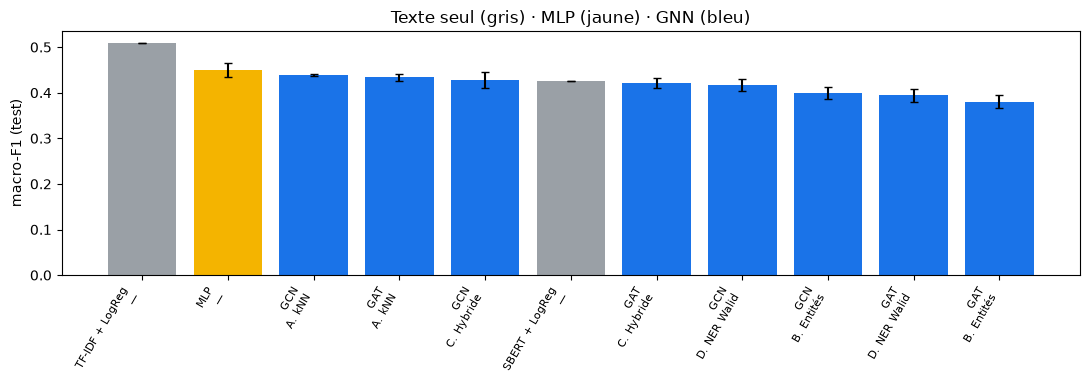

📌 Meilleur sans graphe : 0.509 | meilleur GNN : GCN / A. kNN = 0.439
📌 Gain GNN vs sans graphe : -7.0 points de macro-F1


In [25]:
# Tableau comparatif + graphique
res_df = pd.DataFrame(results).sort_values("macro-F1", ascending=False).reset_index(drop=True)
display(res_df.style.format({"macro-F1": "{:.3f}", "±": "{:.3f}", "Accuracy": "{:.3f}", "val_f1": "{:.3f}"}).background_gradient(subset=["macro-F1"], cmap="Greens"))

plot_df = res_df.copy(); plot_df["label"] = plot_df["Modèle"] + "\n" + plot_df["Graphe"]
colors = plot_df["Famille"].map({"Texte seul": "#9aa0a6", "Features seules": "#f4b400", "GNN": "#1a73e8"})
plt.figure(figsize=(11, 4)); plt.bar(plot_df["label"], plot_df["macro-F1"], yerr=plot_df["±"], color=colors, capsize=3)
plt.xticks(rotation=60, ha="right", fontsize=8); plt.ylabel("macro-F1 (test)"); plt.title("Texte seul (gris) · MLP (jaune) · GNN (bleu)"); plt.tight_layout(); plt.show()

best_text = res_df[res_df["Famille"] != "GNN"]["macro-F1"].max()
best_gnn_row = res_df[res_df["Famille"] == "GNN"].iloc[0]
print(f"📌 Meilleur sans graphe : {best_text:.3f} | meilleur GNN : {best_gnn_row['Modèle']} / {best_gnn_row['Graphe']} = {best_gnn_row['macro-F1']:.3f}")
print(f"📌 Gain GNN vs sans graphe : {100 * (best_gnn_row['macro-F1'] - best_text):+.1f} points de macro-F1")

> 🗣️ **Comment présenter le résultat honnêtement** : si le gain est faible ou négatif, ce n'est pas un échec : regarde l'**homophilie** (section 9). Un GNN aide seulement si les voisins ont souvent le même label. C'est exactement l'analyse attendue pour DS4. Le **choix du modèle** se fait sur la **validation** (jamais sur le test).

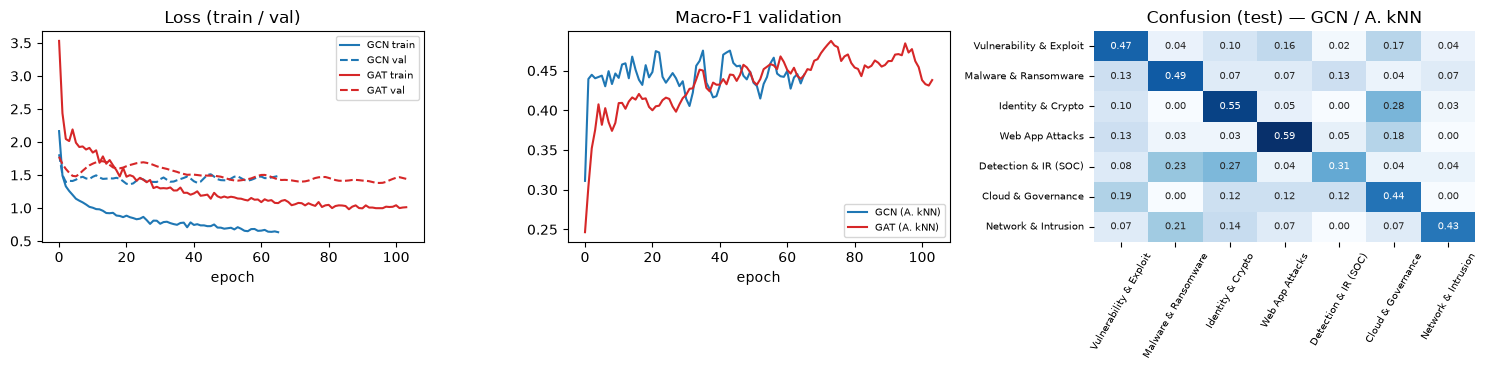

                         precision    recall  f1-score   support

Vulnerability & Exploit      0.732     0.472     0.574       127
   Malware & Ransomware      0.643     0.491     0.557        55
      Identity & Crypto      0.431     0.550     0.484        40
        Web App Attacks      0.434     0.590     0.500        39
   Detection & IR (SOC)      0.381     0.308     0.340        26
     Cloud & Governance      0.137     0.438     0.209        16
    Network & Intrusion      0.353     0.429     0.387        14

               accuracy                          0.483       317
              macro avg      0.444     0.468     0.436       317
           weighted avg      0.566     0.483     0.505       317



In [26]:
# Meilleurs modèles (choisis sur la VALIDATION) : courbes + matrice de confusion
def best_key(model_name):
    keys = [k for k in store if k[0] == model_name]
    return max(keys, key=lambda k: store[k]["val_f1_mean"])

kg, kt = best_key("GCN"), best_key("GAT")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for key, col in [(kg, "tab:blue"), (kt, "tab:red")]:
    h = store[key]["res"]["hist"]
    axes[0].plot(h["train_loss"], color=col, label=f"{key[0]} train"); axes[0].plot(h["val_loss"], color=col, ls="--", label=f"{key[0]} val")
    axes[1].plot(h["val_f1"], color=col, label=f"{key[0]} ({key[1]})")
axes[0].set_title("Loss (train / val)"); axes[0].set_xlabel("epoch"); axes[0].legend(fontsize=7)
axes[1].set_title("Macro-F1 validation"); axes[1].set_xlabel("epoch"); axes[1].legend(fontsize=7)

best_overall = max([k for k in store if k[0] != "MLP"], key=lambda k: store[k]["val_f1_mean"])
dd = datas[best_overall[1]]; te = dd.test_mask.cpu().numpy()
pred = store[best_overall]["res"]["pred"]
cm = confusion_matrix(y[te], pred[te], labels=np.arange(C), normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[2], cbar=False, annot_kws={"size": 7})
axes[2].set_title(f"Confusion (test) — {best_overall[0]} / {best_overall[1]}"); axes[2].tick_params(axis="x", rotation=60, labelsize=7); axes[2].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

print(classification_report(y[te], pred[te], target_names=class_names, digits=3, zero_division=0))

---
# 12) Analyses pour la soutenance
### 12.1 Sur-smoothing : combien de couches ?
Plus on empile de couches GCN, plus les représentations se ressemblent. On le vérifie sur le graphe hybride.

1 couches → macro-F1 0.444


2 couches → macro-F1 0.418


3 couches → macro-F1 0.438


4 couches → macro-F1 0.438


6 couches → macro-F1 0.435


8 couches → macro-F1 0.325


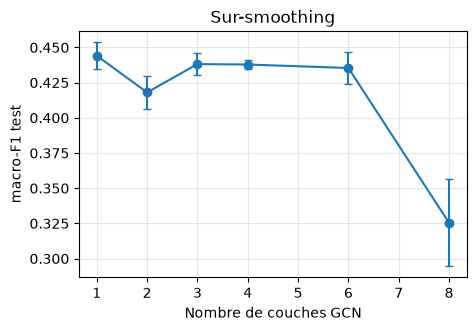

In [27]:
# Profondeur du GCN vs macro-F1
depths = [1, 2, 3, 4, 6, 8]
depth_res = []
for L in depths:
    r = run_config(f"GCN-{L}", lambda L=L: GCN(IN_DIM, 128, C, num_layers=L), datas["C. Hybride"], seeds=(0, 1), **TRAIN_KW)
    depth_res.append((L, r["f1_mean"], r["f1_std"]))
    print(f"{L} couches → macro-F1 {r['f1_mean']:.3f}")
L_, m_, s_ = zip(*depth_res)
plt.figure(figsize=(5, 3.2)); plt.errorbar(L_, m_, yerr=s_, marker="o", capsize=3); plt.xlabel("Nombre de couches GCN"); plt.ylabel("macro-F1 test"); plt.title("Sur-smoothing"); plt.grid(alpha=.3); plt.show()

### 12.2 Interpréter GAT : quels voisins comptent ?
Les poids d'attention $\alpha_{ij}$ sont **lisibles** (même argument d'explicabilité que le Chapitre 2 : « on peut visualiser les poids d'attention »). C'est un atout pour la **traçabilité** du graphe (DS4).

In [28]:
# Voisins les plus « écoutés » par GAT pour un incident de test
gat_key = best_key("GAT")
gat = store[gat_key]["model"]; dd = datas[gat_key[1]]
ei_att, alpha = gat.attention(dd.x, dd.edge_index)
ei_att, alpha = ei_att.cpu().numpy(), alpha.cpu().numpy()
pred_gat = store[gat_key]["res"]["pred"]

test_ids = np.where(dd.test_mask.cpu().numpy())[0]
deg_in = np.bincount(ei_att[1], minlength=N)
node = next((i for i in test_ids if pred_gat[i] == y[i] and deg_in[i] >= 8), int(test_ids[0]))

m = ei_att[1] == node                       # arêtes qui ARRIVENT sur `node`
rows = pd.DataFrame({"voisin": ei_att[0][m], "attention": alpha[m]}).sort_values("attention", ascending=False).head(6)
rows["classe"] = [class_names[y[v]] for v in rows["voisin"]]
rows["extrait"] = [df.loc[v, "question"][:70] for v in rows["voisin"]]
rows["même classe ?"] = [("— (lui-même)" if v == node else ("✅" if y[v] == y[node] else "❌")) for v in rows["voisin"]]
print(f"Incident analysé : « {df.loc[node, 'question'][:110]} »\nClasse réelle : {class_names[y[node]]} | prédite : {class_names[pred_gat[node]]}\n")
rows.round(3).reset_index(drop=True)

Incident analysé : « What is "DOM Clobbering" and how can it be used to escalate or enable a Reflected XSS payload? Provide a conce »
Classe réelle : Web App Attacks | prédite : Web App Attacks



,voisin,attention,classe,extrait,même classe ?
0,23,0.105,Web App Attacks,How can Stored XSS be leveraged to bypass CSRF protection? Explain how,✅
1,42,0.073,Vulnerability & Exploit,Explain why automated static analysis (SAST) often struggles to effect,❌
2,1373,0.071,Web App Attacks,What are the techniques for constructing polyglot XSS vectors that wor,✅
3,40,0.064,Vulnerability & Exploit,How does Angular's built-in sanitizer and context-aware escaping attem,❌
4,46,0.052,Vulnerability & Exploit,"What is a ""prototype pollution"" vulnerability in JavaScript, and how c",❌
5,48,0.051,Web App Attacks,How can client-side template injection (CSTI) lead to DOM XSS? Explain,✅


### 12.3 Visualiser les embeddings (t-SNE)
On compare l'espace des **features SBERT brutes** à l'espace appris par le **GAT** : les classes doivent mieux se séparer après message passing.

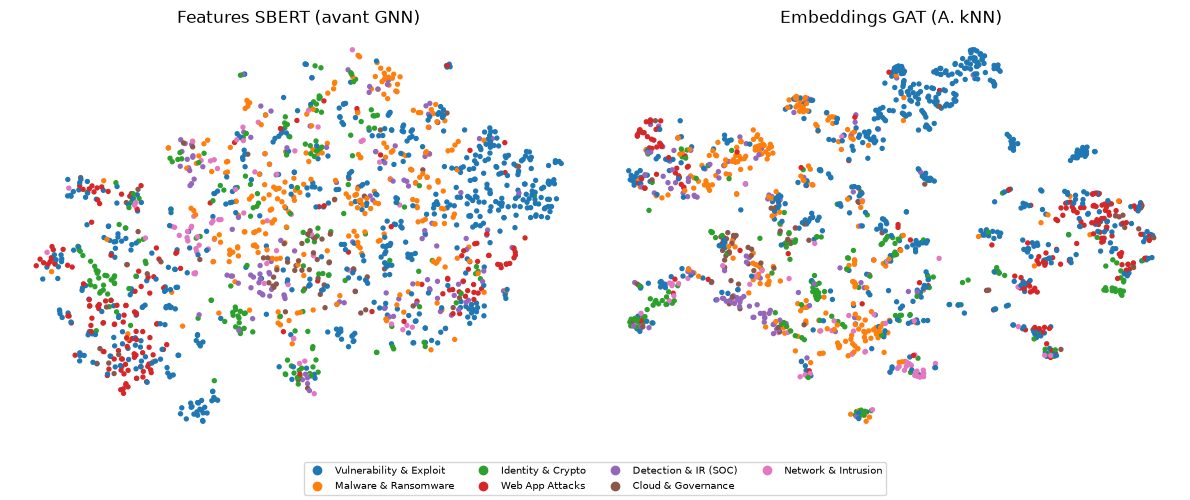

In [29]:
# t-SNE : features brutes vs embeddings GAT
with torch.no_grad():
    _, hid = gat(dd.x, dd.edge_index, return_hidden=True)
Z_gat = hid.cpu().numpy()
sel = np.random.RandomState(0).choice(N, size=min(N, 1500), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, Z, title in [(axes[0], X_sbert, "Features SBERT (avant GNN)"), (axes[1], Z_gat, f"Embeddings GAT ({gat_key[1]})")]:
    E = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(Z[sel])
    ax.scatter(E[:, 0], E[:, 1], c=y[sel], cmap="tab10", vmin=0, vmax=9, s=8); ax.set_title(title); ax.axis("off")
handles = [plt.Line2D([0], [0], marker="o", ls="", color=plt.cm.tab10(i / 9), label=c) for i, c in enumerate(class_names)]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=7); plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

---
# 13) Données de **Walid** : intégration réalisée
L'interface prévue est maintenant branchée : le **graphe D** (section 9) est construit à partir de `data/processed/entities.json`, livré par le NER du Notebook 1, avec le même identifiant `doc_id`, la même projection incident–incident et le même garde-fou anti-fuite que le graphe B. Comparer B (lexique de ce notebook) et D (NER de Walid) mesure l'apport d'un NER plus complet sur l'homophilie et le macro-F1.

In [30]:
comparison_bd = pd.DataFrame([
    {"Graphe": name, "Incidents couverts": f"{(np.bincount(ei[0], minlength=N) > 0).mean():.1%}", **graph_stats(name, ei, y)}
    for name, ei in (("B. Entités", ei_ent), ("D. NER Walid", ei_walid))
]).drop(columns="Graphe").set_index(pd.Index(["B. Entités (lexique 2A)", "D. NER Walid"]))
display(comparison_bd)
display(res_df[res_df["Graphe"].isin(["B. Entités", "D. NER Walid"])][["Modèle", "Graphe", "macro-F1", "±"]].round(3))

,Incidents couverts,Arêtes,Degré moyen,Nœuds isolés,Homophilie
B. Entités (lexique 2A),39.9%,13469,17.00,952,0.339
D. NER Walid,45.1%,11956,15.09,870,0.346


,Modèle,Graphe,macro-F1,±
7,GCN,D. NER Walid,0.417,0.014
8,GCN,B. Entités,0.400,0.013
9,GAT,D. NER Walid,0.394,0.015
10,GAT,B. Entités,0.381,0.014


---
# 14) Export & passation au **Membre 3** (GTN + Leiden)
Le Membre 3 réutilise **ton pipeline PyG** : il n'a pas à refaire la conversion texte → graphe.

In [31]:
# Export des livrables
OUT = str(config.ARTIFACTS / "notebook2a"); os.makedirs(OUT, exist_ok=True)
res_df.to_csv(f"{OUT}/comparatif_macroF1.csv", index=False)
df[["question", "label"]].assign(node_id=np.arange(N), split=np.where(np.isin(np.arange(N), idx_train), "train", np.where(np.isin(np.arange(N), idx_val), "val", "test"))).to_csv(f"{OUT}/incidents_labels_split.csv", index=False)
for gname, ei in graph_edges.items():
    pd.DataFrame(ei.T, columns=["source", "target"]).to_csv(f"{OUT}/edges_{gname[0]}.csv", index=False)
np.save(f"{OUT}/node_features_sbert.npy", X_sbert)
np.save(f"{OUT}/node_embeddings_gat.npy", Z_gat)
torch.save(datas["C. Hybride"].clone().cpu(), f"{OUT}/incident_graph_hybrid.pt")     # rechargement : torch.load(path, weights_only=False)
json.dump({"classes": class_names, "seed": SEED, "k_knn": K, "leak_guard": LEAK_GUARD}, open(f"{OUT}/meta.json", "w"), ensure_ascii=False, indent=2)
print("✅ Fichiers exportés :", os.listdir(OUT))

✅ Fichiers exportés : ['comparatif_macroF1.csv', 'incidents_labels_split.csv', 'edges_A.csv', 'edges_B.csv', 'edges_C.csv', 'edges_D.csv', 'node_features_sbert.npy', 'node_embeddings_gat.npy', 'incident_graph_hybrid.pt', 'meta.json']


---
## ✅ 15) Auto-vérifications
Comme dans le Workshop : ces cellules vérifient brièvement que chaque partie a été exécutée correctement.

In [32]:
# Vérifications automatiques
checks = []
def check(name, cond): 
    checks.append(cond); print(("✅ " if cond else "❌ ") + name)

dd = datas["C. Hybride"]
tr, va, te = dd.train_mask.cpu().numpy(), dd.val_mask.cpu().numpy(), dd.test_mask.cpu().numpy()
check("Masques train/val/test disjoints", not ((tr & va).any() or (tr & te).any() or (va & te).any()))
check("Tous les nœuds sont dans un split", (tr | va | te).all())
check("edge_index valide (indices < N, forme [2,E])", dd.edge_index.shape[0] == 2 and int(dd.edge_index.max()) < N)
check("Graphe non orienté (A→B ⇒ B→A)", {tuple(e) for e in dd.edge_index.T.tolist()} == {(b, a) for a, b in dd.edge_index.T.tolist()})
check("Pas de fuite : aucun mot-clé d'étiquetage dans les features", (not LEAK_GUARD) or df["text_feat"].apply(lambda t: ALL_LABEL_RX.search(t) is None).all())
check("Lexique d'entités disjoint des règles d'étiquetage", all(ALL_LABEL_RX.search(t) is None for typ in ENTITY_LEXICON for t in ENTITY_LEXICON[typ] if t not in dropped))
check("Baselines texte seul calculées", any(r["Famille"] == "Texte seul" for r in results))
check("GCN et GAT entraînés sur les 4 graphes", all((m, g) in store for m in ("GCN", "GAT") for g in graph_edges))
check("Tableau comparatif disponible", len(res_df) >= 8)
print(f"\n{sum(checks)}/{len(checks)} vérifications OK")
if not all(checks): print("⚠️ Relis la section correspondante puis ré-exécute.")

✅ Masques train/val/test disjoints
✅ Tous les nœuds sont dans un split
✅ edge_index valide (indices < N, forme [2,E])
✅ Graphe non orienté (A→B ⇒ B→A)


✅ Pas de fuite : aucun mot-clé d'étiquetage dans les features
✅ Lexique d'entités disjoint des règles d'étiquetage
✅ Baselines texte seul calculées
✅ GCN et GAT entraînés sur les 4 graphes
✅ Tableau comparatif disponible

9/9 vérifications OK


---
## 🎯 Check-list soutenance
- **Problème** : relier incidents, vecteurs et cibles (OM4) ; classer les incidents en s'appuyant sur la **structure** (DS4).
- **Pipeline** : texte → SBERT → graphe (kNN / entités / hybride / NER de Walid) → `Data` PyG → GCN / GAT.
- **Résultat clé** : tableau **texte seul vs GNN** (macro-F1 moyenne ± écart-type sur 3 graines, choix sur validation).
- **Concepts** : message passing · GCN (poids fixes) vs GAT (attention, lien Chapitre 2) · sur-smoothing · transductif · macro-F1 · homophilie · anti-fuite.
- **Honnêteté** : labels = supervision faible (règles de mots-clés) → à remplacer par les labels de l'équipe dès qu'ils existent ; le graphe NER de Walid est intégré (graphe D, section 13).
- **Passation** : `incident_graph_hybrid.pt` + embeddings → Membre 3 (GTN, clustering Leiden).

---
## 📊 16) Métriques exportées
Les résultats sont écrits dans `reports/metrics/notebook2a_metrics.json`, lu par le notebook maître et la page *Métriques* du MVP.

In [33]:
best_gnn = res_df[res_df["Famille"] == "GNN"].iloc[0]
notebook2a_metrics = {
    "n_incidents": int(N), "classes": class_names,
    "graphs": gstats.to_dict(orient="records"),
    "results": res_df[["Modèle", "Famille", "Graphe", "macro-F1", "±", "Accuracy", "val_f1"]].to_dict(orient="records"),
    "best_text_only_macro_f1": float(best_text),
    "best_gnn": {"model": best_gnn["Modèle"], "graph": best_gnn["Graphe"], "macro_f1": float(best_gnn["macro-F1"])},
    "cora": {name: {"f1_mean": r["f1_mean"], "f1_std": r["f1_std"]} for name, r in cora_res.items()},
    "oversmoothing": [{"layers": L, "macro_f1": m, "std": s} for L, m, s in depth_res],
}
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)
(config.METRICS_DIR / "notebook2a_metrics.json").write_text(json.dumps(notebook2a_metrics, indent=2, ensure_ascii=False, default=float))
print(json.dumps({k: notebook2a_metrics[k] for k in ("best_text_only_macro_f1", "best_gnn")}, indent=2, ensure_ascii=False))

{
  "best_text_only_macro_f1": 0.5091639455130149,
  "best_gnn": {
    "model": "GCN",
    "graph": "A. kNN",
    "macro_f1": 0.43873666259050137
  }
}
